# Looking at our Seurat objects and converting them for Scanpy

**Alyona you do not have to run this**

In [1]:
library(Seurat)
library(sceasy)
library(qs2)
library(data.table)

Loading required package: SeuratObject

Loading required package: sp

Loading required package: sp


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


Loading required package: reticulate

qs2 0.1.5



We read in my Seurat object for the curated 31k atlas. I keep the "RNA" assay only, the other Seurat specific stuff was used for defining cell types and dealing with batch effects.

In [2]:
curated_6dpf_qs2 = "/scratch/cros/10dpf_explorations/202407_CuratedTotal6dpfAtlas_31knuclei_final.qs2"
curated_6dpf <- qs_read(file = curated_6dpf_qs2, nthreads = 8) # 20s
DefaultAssay(curated_6dpf) <- "RNA"
curated_6dpf

An object of class Seurat 
122676 features across 30850 samples within 3 assays 
Active assay: RNA (64955 features, 0 variable features)
 2 layers present: counts, data
 2 other assays present: SCT, integrated
 2 dimensional reductions calculated: pca, umap

Seurat just sucks in general...

In [3]:
curated_6dpf[['RNA']]

Assay data with 64955 features for 30850 cells
First 10 features:
 XLOC-000001, XLOC-000002, XLOC-000003, XLOC-000004, XLOC-000005,
XLOC-000006, XLOC-000007, XLOC-000008, XLOC-000009, XLOC-000010 

It is easier to just recreate an object with just the RNA assay.

In [4]:
curated_6dpf_cleaner <- CreateSeuratObject(counts=curated_6dpf[['RNA']], meta.data = curated_6dpf@meta.data)
curated_6dpf_cleaner
head(curated_6dpf@meta.data)

An object of class Seurat 
64955 features across 30850 samples within 1 assay 
Active assay: RNA (64955 features, 0 variable features)
 2 layers present: counts, data

,orig.ident,nCount_RNA,nFeature_RNA,percent.mtdna,percent.rrna,percent.goodgenes,seurat_clusters,S.Score,G2M.Score,Phase,⋯,nFeature_SCT,curated_high_res_annotations,coarse_clade_membership,celltype_family_20240924,group_full,group_slug,group_color,clade,subclade,subsubclade
,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<chr>,⋯,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
SN001_AAACCCAAGTCGCCAC-1,SN001,1284,922,0.30935808,0.3866976,99.30394,9,-0.11046880,-0.12180932,G1,⋯,916,nocladesub2,noclade,epidermis,Epidermis,epidermis,#5B9BD5,noclade,nocladesub2,nocladesub2
SN001_AAACCCACAAGTAGTA-1,SN001,2293,1612,0.21720243,0.1737619,99.60904,4,0.01645752,0.10693499,G2M,⋯,1601,clade6sub16,clade6,epidermis,Epidermis,epidermis,#5B9BD5,clade6,clade6sub16,clade6sub16
SN001_AAACGAAGTGTTGCCG-1,SN001,2040,1399,0.14634146,0.3414634,99.51220,26,-0.14393175,-0.09518247,G1,⋯,1391,nocladesub21,noclade,enteric_nervous_system,Enteric nervous system,enteric_ns,#92D050,noclade,nocladesub21,nocladesub21
SN001_AAACGAAGTTGAGGAC-1,SN001,1030,762,0.09615385,0.8653846,99.03846,17,0.01502144,-0.16163565,S,⋯,757,clade11sub28subsub3,clade11,provisional:neurons,Dbx + related,dbx_related,#00008B,clade11,clade11sub28,clade11sub28subsub3
SN001_AAACGCTGTACAGAGC-1,SN001,1467,960,0.27008778,0.6752194,99.05469,3,-0.05308446,-0.16076602,G1,⋯,954,clade3.1sub7-16,clade3.1,somatic_musculature,Somatic musculature,somatic_muscle,#FF0000,clade3.1,clade3.1sub7-16,clade3.1sub7-16
SN001_AAAGGATAGATCGCCC-1,SN001,958,740,0.30895984,1.0298661,98.66117,13,-0.10674803,-0.17373766,G1,⋯,735,clade11sub45subsub1,clade11,apical_nervous_system,Anterior nervous system,ANS,#DD5E82,clade11,clade11sub45,clade11sub45subsub1


I will save  PCA and UMAP for this at least.

In [5]:
for (red in c("pca", "umap")){
    curated_6dpf_cleaner[[red]] <- CreateDimReducObject(
        embeddings = Embeddings(curated_6dpf,reduction = red),
        loadings = Loadings(curated_6dpf,reduction = red),
        assay="RNA"
    )
}
curated_6dpf_cleaner

An object of class Seurat 
64955 features across 30850 samples within 1 assay 
Active assay: RNA (64955 features, 0 variable features)
 2 layers present: counts, data
 2 dimensional reductions calculated: pca, umap

I have to save as RDS.

In [6]:
saveRDS(curated_6dpf_cleaner,file = "/scratch/cros/curated_6dpf_cleaner.RDS")

Little plot to show the new object is still fine...

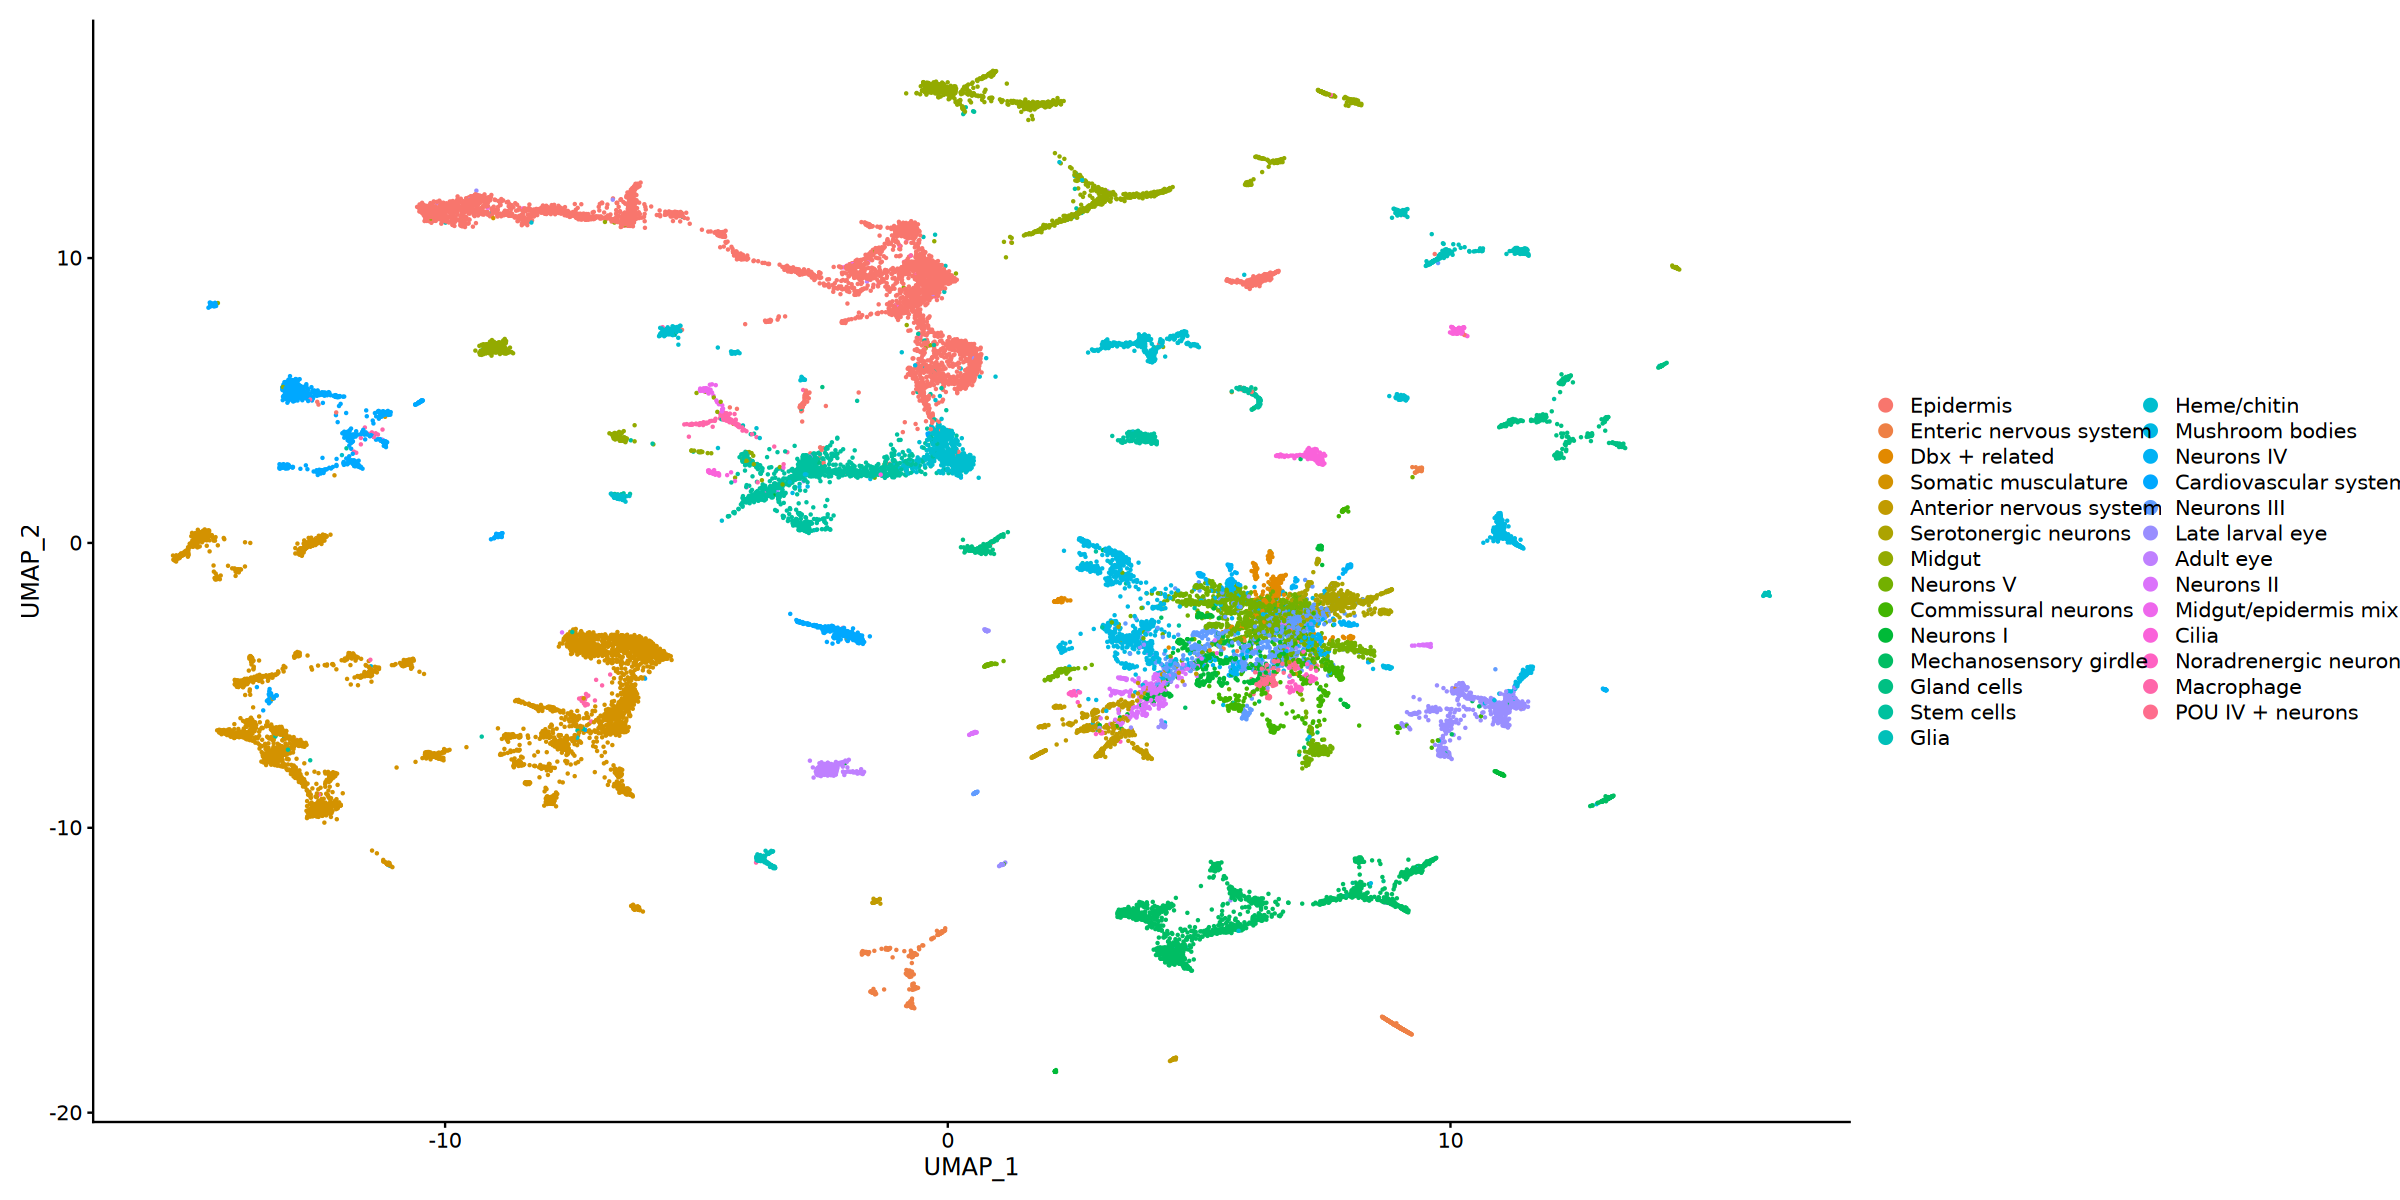

In [7]:
Idents(curated_6dpf_cleaner) <- "group_full"
options(repr.plot.height = 10,repr.plot.width = 20)
DimPlot(curated_6dpf_cleaner)

I am using next https://github.com/settylab/convert2anndata which requires a manual installation but is fast...

    Rscript -e "convert2anndata::cli_convert()"  --input /scratch/cros/curated_6dpf_cleaner.RDS --output /scratch/cros/seurat_curated_6dpf.h5ad